In [9]:
import pandas as pd
import re

df = pd.read_csv("Keyword_Dataset_Clean.csv")

print("Số lượng keyword:", len(df))
print(df.columns.tolist())

Số lượng keyword: 500
['Clean_ID', 'Keyword_Original', 'Keyword', 'Currency', 'Avg. monthly searches', 'Thay đổi trong ba tháng', 'Thay đổi so với cùng kỳ năm trước', 'Competition', 'Competition (indexed value)', 'Top of page bid (low range)', 'Top of page bid (high range)', 'Relevance_Score', 'Selection_Status']


In [10]:
import os
# Liệt kê các tệp tin trong thư mục hiện tại để kiểm tra đường dẫn
print(os.listdir('.'))

['.config', 'Keyword_Dataset_Clean.csv', 'Keyword_Dataset_Search_Intent.csv', 'sample_data']


In [ ]:
from google.colab import files
# Tải tệp tin 'Keyword_Dataset_Clean.csv' từ máy tính của bạn lên Colab
uploaded = files.upload()

In [11]:
#Kiểm tra dữ liệu
df.head(10)

,Clean_ID,Keyword_Original,Keyword,Currency,Avg. monthly searches,Thay đổi trong ba tháng,Thay đổi so với cùng kỳ năm trước,Competition,Competition (indexed value),Top of page bid (low range),Top of page bid (high range),Relevance_Score,Selection_Status
0,1,bình giữ nhiệt,bình giữ nhiệt,VND,50000,0%,0%,Cao,100.0,545.0,12191.0,4,KEEP
1,2,bình giữ nhiệt cao cấp,bình giữ nhiệt cao cấp,VND,5000,0%,0%,Cao,100.0,661.0,2682.0,4,KEEP
2,3,bình giữ nhiệt elmich,bình giữ nhiệt elmich,VND,5000,0%,0%,Cao,100.0,794.0,4962.0,4,KEEP
3,4,bình giữ nhiệt lock and lock,bình giữ nhiệt lock and lock,VND,5000,0%,0%,Cao,100.0,363.0,3088.0,4,KEEP
4,5,bình giữ nhiệt lock lock,bình giữ nhiệt lock lock,VND,5000,0%,0%,Cao,100.0,356.0,3253.0,4,KEEP
5,6,bình giữ nhiệt lock n lock,bình giữ nhiệt lock n lock,VND,5000,0%,0%,Cao,100.0,356.0,3253.0,4,KEEP
6,7,bình giữ nhiệt lock&lock,bình giữ nhiệt lock&lock,VND,5000,0%,0%,Cao,100.0,356.0,3253.0,4,KEEP
7,8,bình giữ nhiệt stanley,bình giữ nhiệt stanley,VND,5000,0%,900%,Cao,100.0,448.0,2680.0,4,KEEP
8,9,bình giữ nhiệt starbucks,bình giữ nhiệt starbucks,VND,5000,0%,0%,Cao,100.0,655.0,2689.0,4,KEEP
9,10,bình giữ nhiệt thermos,bình giữ nhiệt thermos,VND,5000,0%,0%,Cao,100.0,622.0,2682.0,4,KEEP


In [12]:
df["Keyword"] = (
    df["Keyword"]
    .astype(str)
    .str.lower()
    .str.strip()
)

print(df["Keyword"].head(10))

0                  bình giữ nhiệt
1          bình giữ nhiệt cao cấp
2           bình giữ nhiệt elmich
3    bình giữ nhiệt lock and lock
4        bình giữ nhiệt lock lock
5      bình giữ nhiệt lock n lock
6        bình giữ nhiệt lock&lock
7          bình giữ nhiệt stanley
8        bình giữ nhiệt starbucks
9          bình giữ nhiệt thermos
Name: Keyword, dtype: object


In [17]:
df[["Keyword", "Search_Intent"]].head(20)

,Keyword,Search_Intent
0,bình giữ nhiệt,Unclassified
1,bình giữ nhiệt cao cấp,Unclassified
2,bình giữ nhiệt elmich,Navigational
3,bình giữ nhiệt lock and lock,Navigational
4,bình giữ nhiệt lock lock,Navigational
5,bình giữ nhiệt lock n lock,Unclassified
6,bình giữ nhiệt lock&lock,Unclassified
7,bình giữ nhiệt stanley,Unclassified
8,bình giữ nhiệt starbucks,Unclassified
9,bình giữ nhiệt thermos,Navigational


In [11]:
#Xóa keyword trùng
df = df.drop_duplicates(subset=["Keyword"])

In [15]:
#Sử dụng Regex
def clean_keyword(keyword):
    keyword = str(keyword).lower()
    keyword = re.sub(r"\s+", " ", keyword)
    keyword = keyword.strip()
    return keyword

df["Keyword"] = df["Keyword"].apply(clean_keyword)

In [15]:
#kiểm tra lại
print("Số keyword sau khi loại trùng:", len(df))

Số keyword sau khi loại trùng: 500


In [17]:
#regex
r"\s+"

'\\s+'

In [18]:
def classify_intent(keyword):
    keyword = keyword.lower().strip()

    # Navigational
    if re.search(
        r"\b(locknlock|lock and lock|lock lock|elmich|thermos|tupperware|yeti)\b",
        keyword
    ):
        return "Navigational"

    # Transactional
    if re.search(
        r"\b(mua|giá|gia|shop|cửa hàng|online|đặt|dat|bán|ban)\b",
        keyword
    ):
        return "Transactional"

    # Commercial
    if re.search(
        r"\b(tốt|tot|tốt nhất|tot nhat|review|đánh giá|danh gia|so sánh|so sanh|nên mua|nen mua|loại nào|loai nao)\b",
        keyword
    ):
        return "Commercial"

    # Informational
    if re.search(
        r"\b(cách|cach|là gì|la gi|như thế nào|nhu the nao|bao lâu|tại sao|tai sao|vì sao|vi sao)\b",
        keyword
    ):
        return "Informational"

    return "Unclassified"


df["Search_Intent"] = df["Keyword"].apply(classify_intent)

In [19]:
df[["Keyword", "Search_Intent"]].head(20)

,Keyword,Search_Intent
0,bình giữ nhiệt,Unclassified
1,bình giữ nhiệt cao cấp,Unclassified
2,bình giữ nhiệt elmich,Navigational
3,bình giữ nhiệt lock and lock,Navigational
4,bình giữ nhiệt lock lock,Navigational
5,bình giữ nhiệt lock n lock,Unclassified
6,bình giữ nhiệt lock&lock,Unclassified
7,bình giữ nhiệt stanley,Unclassified
8,bình giữ nhiệt starbucks,Unclassified
9,bình giữ nhiệt thermos,Navigational


In [21]:
intent_count = df["Search_Intent"].value_counts()

print(intent_count)

Search_Intent
Unclassified     405
Navigational      64
Commercial        17
Transactional      9
Informational      5
Name: count, dtype: int64


In [20]:
df.to_csv(
    "Keyword_Dataset_Search_Intent.csv",
    index=False,
    encoding="utf-8-sig"
)

In [21]:
df["Search_Intent"].value_counts()

,count
Search_Intent,
Unclassified,405
Navigational,64
Commercial,17
Transactional,9
Informational,5


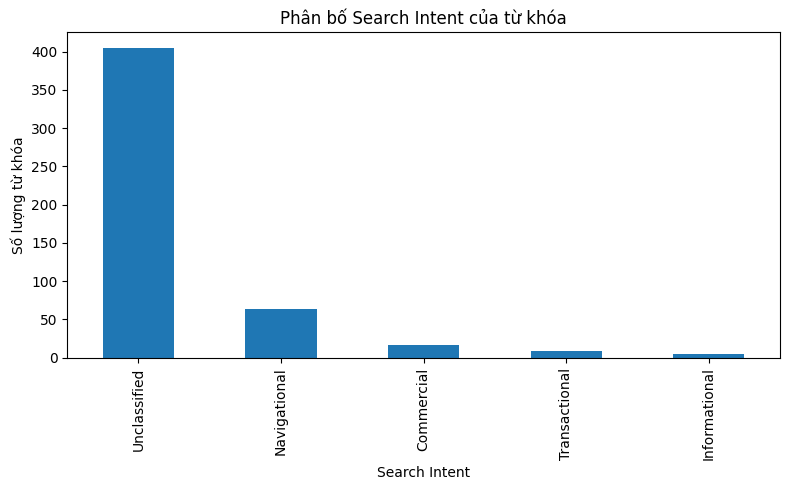

In [22]:
import matplotlib.pyplot as plt

intent_counts = df["Search_Intent"].value_counts()

plt.figure(figsize=(8, 5))
intent_counts.plot(kind="bar")

plt.title("Phân bố Search Intent của từ khóa")
plt.xlabel("Search Intent")
plt.ylabel("Số lượng từ khóa")

plt.tight_layout()
plt.savefig("Intent_Chart.png", dpi=300)
plt.show()

In [25]:
# Đếm số lượng từng Search Intent
intent_counts = df["Search_Intent"].value_counts()

# Tính tỷ lệ phần trăm
intent_percent = (
    df["Search_Intent"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Tạo bảng tổng hợp
intent_summary = pd.DataFrame({
    "Số lượng": intent_counts,
    "Tỷ lệ (%)": intent_percent
})

print(intent_summary)

print("Tổng tỷ lệ:", intent_summary["Tỷ lệ (%)"].sum(), "%")


               Số lượng  Tỷ lệ (%)
Search_Intent                     
Unclassified        405       81.0
Navigational         64       12.8
Commercial           17        3.4
Transactional         9        1.8
Informational         5        1.0
Tổng tỷ lệ: 100.0 %


In [26]:
# BẢNG 1: Keyword → Intent
keyword_intent = df[["Keyword", "Search_Intent"]].copy()

# BẢNG 2: Tổng số lượng + tỷ lệ
intent_summary = (
    df["Search_Intent"]
    .value_counts()
    .rename_axis("Search Intent")
    .reset_index(name="Số lượng")
)

intent_summary["Tỷ lệ (%)"] = (
    intent_summary["Số lượng"]
    / intent_summary["Số lượng"].sum()
    * 100
).round(2)

print("===== BẢNG KEYWORD → INTENT =====")
display(keyword_intent)

print("===== BẢNG TỔNG HỢP SEARCH INTENT =====")
display(intent_summary)

===== BẢNG KEYWORD → INTENT =====


,Keyword,Search_Intent
0,bình giữ nhiệt,Unclassified
1,bình giữ nhiệt cao cấp,Unclassified
2,bình giữ nhiệt elmich,Navigational
3,bình giữ nhiệt lock and lock,Navigational
4,bình giữ nhiệt lock lock,Navigational
...,...,...
495,bình giữ nhiệt emsa samba,Unclassified
496,bình giữ nhiệt emsa samba 1l,Unclassified
497,bình giữ nhiệt ensure 280ml,Unclassified
498,bình giữ nhiệt ernesto,Unclassified


===== BẢNG TỔNG HỢP SEARCH INTENT =====


,Search Intent,Số lượng,Tỷ lệ (%)
0,Unclassified,405,81.0
1,Navigational,64,12.8
2,Commercial,17,3.4
3,Transactional,9,1.8
4,Informational,5,1.0


In [30]:
# Tạo bảng tổng hợp Search Intent
intent_summary = (
    df["Search_Intent"]
    .value_counts()
    .rename_axis("Search Intent")
    .reset_index(name="Số lượng")
)

# Tính tỷ lệ %
tong = intent_summary["Số lượng"].sum()

intent_summary["Tỷ lệ (%)"] = (
    intent_summary["Số lượng"] / tong * 100
).round(2)

# Hiển thị bảng
display(intent_summary)

# Xuất Excel
with pd.ExcelWriter("Search_Intent_Result.xlsx", engine="openpyxl") as writer:
    df[["Keyword", "Search_Intent"]].to_excel(
        writer,
        sheet_name="Keyword_Intent",
        index=False
    )

    intent_summary.to_excel(
        writer,
        sheet_name="Intent_Summary",
        index=False
    )

print("Đã tạo file Search_Intent_Result.xlsx")

,Search Intent,Số lượng,Tỷ lệ (%)
0,Unclassified,405,81.0
1,Navigational,64,12.8
2,Commercial,17,3.4
3,Transactional,9,1.8
4,Informational,5,1.0


Đã tạo file Search_Intent_Result.xlsx
